In [1]:
# Parameters
ticker = "AAPL"
start_date = "2024-01-01"
end_date = "2024-12-31"
db_path = "data/data.db"

In [2]:
# Parameters
ticker = "TSLA"
start_date = "2025-06-01"
end_date = "2025-11-30"
db_path = "data/data.db"


In [3]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Connect and fetch cleaned data for the specific ticker and window
conn = sqlite3.connect(db_path)
query = """
SELECT ts, ticker, open, high, low, close, adj_close, volume
FROM ohlc_hw_cleaned
WHERE ticker = ? AND ts BETWEEN ? AND ?
ORDER BY ts ASC
"""

df = pd.read_sql_query(query, conn, params=(ticker, start_date, end_date))
conn.close()

# Validate history length
df["ts"] = pd.to_datetime(df["ts"])
n_obs = len(df)
print(f"{ticker} from {start_date} to {end_date}: {n_obs} trading days")

if n_obs < 2:
    raise ValueError(f"Insufficient price history for {ticker} in the selected range.")

display(df.head(3))
display(df.tail(3))

TSLA from 2025-06-01 to 2025-11-30: 126 trading days


,ts,ticker,open,high,low,close,adj_close,volume
0,2025-06-02,TSLA,343.5,348.02,333.33,342.69,342.69,81873829
1,2025-06-03,TSLA,346.6,355.40,343.04,344.27,344.27,99324544
2,2025-06-04,TSLA,345.1,345.60,327.33,332.05,332.05,98912100


,ts,ticker,open,high,low,close,adj_close,volume
123,2025-11-25,TSLA,414.42,420.48,405.95,419.40,419.40,71915624
124,2025-11-26,TSLA,423.95,426.94,416.89,426.58,426.58,63463000
125,2025-11-28,TSLA,426.59,432.93,426.20,430.17,430.17,36252900


In [4]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns using adjusted close prices."""
    return np.log(prices / prices.shift(1))

def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate 20-day annualized rolling volatility."""
    return returns.rolling(window=window).std() * np.sqrt(252)

def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Calculate per-date drawdown from peak using adjusted close."""
    cum_max = prices.cummax()
    return (prices - cum_max) / cum_max

def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate annualized Sharpe ratio using log returns."""
    clean_returns = returns.dropna()
    if len(clean_returns) < 2 or clean_returns.std() == 0:
        return np.nan
    ann_mean = clean_returns.mean() * 252
    ann_std = clean_returns.std() * np.sqrt(252)
    return (ann_mean - risk_free_rate) / ann_std

# Apply risk metrics
df["log_return"] = calculate_returns(df["adj_close"])
df["rolling_vol"] = calculate_volatility(df["log_return"], window=20)
df["drawdown"] = calculate_max_drawdown(df["adj_close"])
df["ma_50"] = df["adj_close"].rolling(window=50).mean()

sharpe = calculate_sharpe_ratio(df["log_return"])
print(f"Annualized Sharpe Ratio: {sharpe:.2f}")

Annualized Sharpe Ratio: 0.81


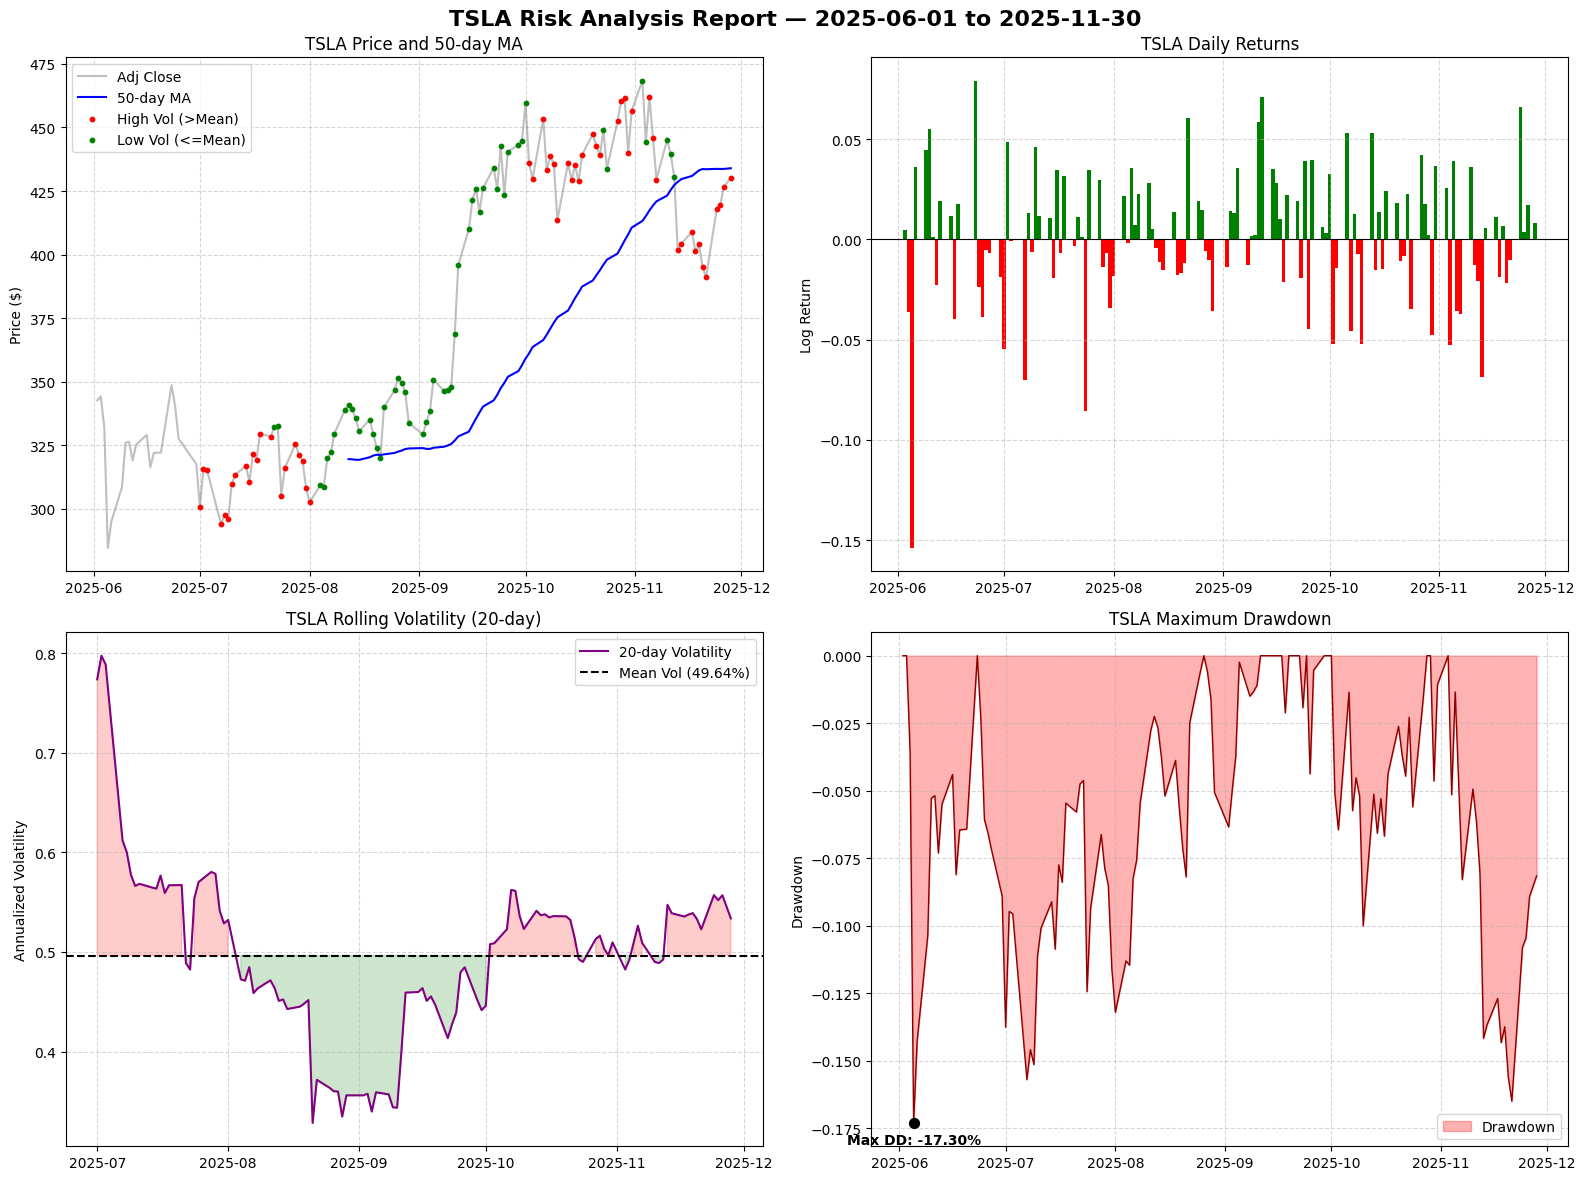

In [5]:
# Cell 4: 2x2 Risk Analysis Visualizations
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(f"{ticker} Risk Analysis Report — {start_date} to {end_date}", fontsize=16, fontweight="bold")

mean_vol = df["rolling_vol"].mean()

# 1. Top Left - Price Chart with 50-day MA
ax1 = axes[0, 0]
ax1.plot(df["ts"], df["adj_close"], label="Adj Close", color="gray", alpha=0.5)
ax1.plot(df["ts"], df["ma_50"], label="50-day MA", color="blue", linewidth=1.5)

high_vol = df["rolling_vol"] > mean_vol
ax1.scatter(df.loc[high_vol, "ts"], df.loc[high_vol, "adj_close"], color="red", s=10, label="High Vol (>Mean)", zorder=3)
ax1.scatter(df.loc[~high_vol & df["rolling_vol"].notna(), "ts"], df.loc[~high_vol & df["rolling_vol"].notna(), "adj_close"], color="green", s=10, label="Low Vol (<=Mean)", zorder=3)

ax1.set_title(f"{ticker} Price and 50-day MA")
ax1.set_ylabel("Price ($)")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()

# 2. Top Right - Daily Returns
ax2 = axes[0, 1]
colors = ["green" if r >= 0 else "red" for r in df["log_return"]]
ax2.bar(df["ts"], df["log_return"], color=colors, width=1.0)
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_title(f"{ticker} Daily Returns")
ax2.set_ylabel("Log Return")
ax2.grid(True, linestyle="--", alpha=0.5)

# 3. Bottom Left - Rolling Volatility (20-day)
ax3 = axes[1, 0]
ax3.plot(df["ts"], df["rolling_vol"], color="purple", label="20-day Volatility")
if not np.isnan(mean_vol):
    ax3.axhline(mean_vol, color="black", linestyle="--", label=f"Mean Vol ({mean_vol:.2%})")
    ax3.fill_between(df["ts"], df["rolling_vol"], mean_vol, where=(df["rolling_vol"] > mean_vol), color="red", alpha=0.2)
    ax3.fill_between(df["ts"], df["rolling_vol"], mean_vol, where=(df["rolling_vol"] <= mean_vol), color="green", alpha=0.2)
ax3.set_title(f"{ticker} Rolling Volatility (20-day)")
ax3.set_ylabel("Annualized Volatility")
ax3.grid(True, linestyle="--", alpha=0.5)
ax3.legend()

# 4. Bottom Right - Maximum Drawdown
ax4 = axes[1, 1]
ax4.fill_between(df["ts"], df["drawdown"], 0, color="red", alpha=0.3, label="Drawdown")
ax4.plot(df["ts"], df["drawdown"], color="darkred", linewidth=1)

min_dd_idx = df["drawdown"].idxmin()
if pd.notna(min_dd_idx):
    min_dd_date = df.loc[min_dd_idx, "ts"]
    min_dd_val = df.loc[min_dd_idx, "drawdown"]
    ax4.scatter(min_dd_date, min_dd_val, color="black", s=50, zorder=5)
    ax4.annotate(f"Max DD: {min_dd_val:.2%}", (min_dd_date, min_dd_val),
                 textcoords="offset points", xytext=(0, -15), ha="center", fontweight="bold")

ax4.set_title(f"{ticker} Maximum Drawdown")
ax4.set_ylabel("Drawdown")
ax4.grid(True, linestyle="--", alpha=0.5)
ax4.legend()

plt.tight_layout()
plt.show()

In [6]:
# Cell 5: Summary Statistics Table
clean_rets = df["log_return"].dropna()
n_rets = len(clean_rets)

total_return = (df["adj_close"].iloc[-1] / df["adj_close"].iloc[0]) - 1
ann_return = np.exp(clean_rets.sum() * 252 / n_rets) - 1 if n_rets > 0 else np.nan
ann_vol = clean_rets.std() * np.sqrt(252) if n_rets > 1 else np.nan
max_dd = df["drawdown"].min()
best_day = clean_rets.max() if n_rets > 0 else np.nan
worst_day = clean_rets.min() if n_rets > 0 else np.nan

pos_rets = clean_rets[clean_rets > 0]
neg_rets = clean_rets[clean_rets < 0]

pos_days_pct = (len(pos_rets) / n_rets) if n_rets > 0 else np.nan
avg_up = pos_rets.mean() if len(pos_rets) > 0 else np.nan
avg_down = neg_rets.mean() if len(neg_rets) > 0 else np.nan

summary_stats = pd.DataFrame({
    "Metric": [
        "Total Return",
        "Annualized Return",
        "Annualized Volatility",
        "Sharpe Ratio",
        "Maximum Drawdown",
        "Best Day",
        "Worst Day",
        "Positive Days",
        "Average Up Day",
        "Average Down Day"
    ],
    "Value": [
        f"{total_return:+.2%}",
        f"{ann_return:+.2%}",
        f"{ann_vol:.2%}",
        f"{sharpe:.2f}" if pd.notna(sharpe) else "N/A",
        f"{max_dd:.2%}",
        f"{best_day:+.2%}",
        f"{worst_day:+.2%}",
        f"{pos_days_pct:.1%}",
        f"{avg_up:+.2%}" if pd.notna(avg_up) else "N/A",
        f"{avg_down:+.2%}" if pd.notna(avg_down) else "N/A"
    ]
})

display(summary_stats)

,Metric,Value
0,Total Return,+25.53%
1,Annualized Return,+58.15%
2,Annualized Volatility,53.85%
3,Sharpe Ratio,0.81
4,Maximum Drawdown,-17.30%
5,Best Day,+7.91%
6,Worst Day,-15.38%
7,Positive Days,55.2%
8,Average Up Day,+2.49%
9,Average Down Day,-2.66%
